# Hilo Carga

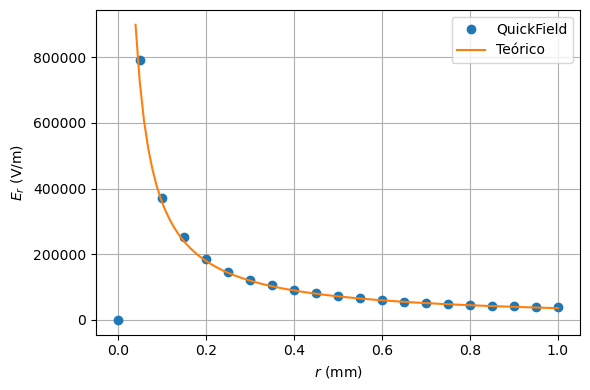

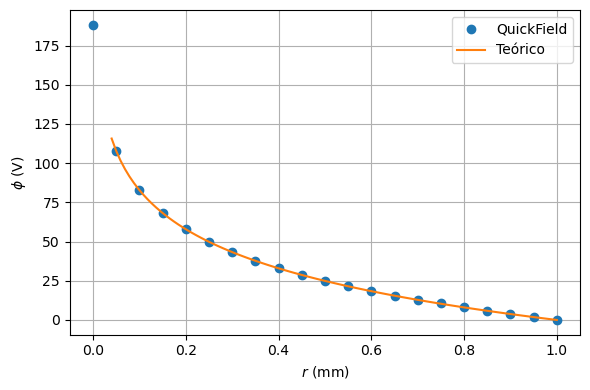

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


file_name = "hilo_carga.txt"

########################################################################################
# Leer ignorando el encabezado y asignando a cada columna su nombre

# (para problema electrostático)
data = pd.read_csv(file_name, sep=r"\s+", skiprows=1,
                   names=["L_mm", "x_mm", "y_mm", "Nx", "Ny", "U_V", "E_V/m",
                          "Ex_V/m", "Ey_V/m", "En_V/m", "Et_V/m", "D_C/m2",
                          "Dx_C/m2", "Dy_C/m2", "Dn_C/m2", "Dt_C/m2", "epsilon_r", "w_J/m3"])

# (para problema magnetostático)
# data = pd.read_csv(file_name, sep=r"\s+", skiprows=1,
#                    names=["L_mm", "z_mm", "r_mm", "Nx", "Ny", "rA_Wb", "B_T",
#                           "Bz_T", "Br_T", "Bn_T", "Bt_T", "H_A/m",
#                           "Hz_A/m", "Hr_A/m", "Hn_A/m", "Ht_A/m", "mu_r", "w_J/m3"])

########################################################################################
# Extraer columnas de interés 
L = data["L_mm"]
E = data["E_V/m"]
U = data["U_V"]

########################################################################################
# Resultado teórico: campo y potencial de un plano cargado infinito
eps0 = 8.854e-12  # permitividad del vacío
lambda_carga = 2e-9 # C/m
r = np.linspace(0.04,np.max(L),101) # malla de puntos del resultado teórico


E_teo = lambda_carga / (2 * np.pi * eps0 * r * 1e-3)
r_0 = 1  # posición del origen de potencial (mm)

U_teo = lambda_carga / (2 * np.pi * eps0) * np.log(r_0/r)

########################################################################################
# Graficar 
plt.figure(figsize=(6, 4))
plt.plot(L, E, 'o', label='QuickField')
plt.plot(r, E_teo, '-', label='Teórico')
plt.xlabel(r"$r$ (mm)")
plt.ylabel(r"$E_r$ (V/m)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('plot_hilo_carga_E.png')
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(L, U, 'o', label='QuickField')
plt.plot(r, U_teo, '-', label='Teórico')
plt.xlabel(r"$r$ (mm)")
plt.ylabel(r"$\phi$ (V)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('plot_hilo_carga_U.png')
plt.show()

# Plano de carga.

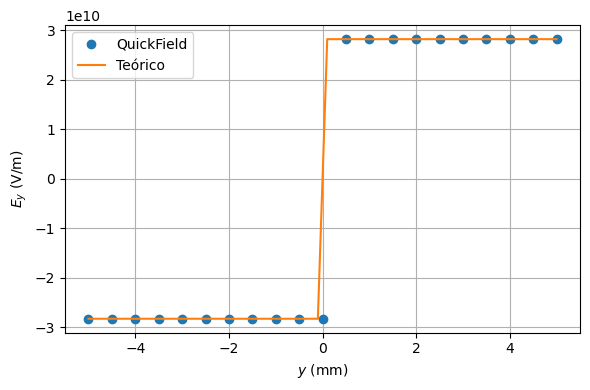

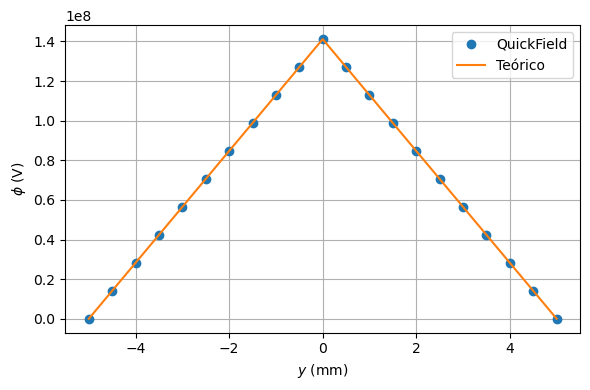

In [42]:

########################################################################################
# Cargar el archivo de texto
file_name = "plano_carga.txt"

########################################################################################
# Leer ignorando el encabezado y asignando a cada columna su nombre

# (para problema electrostático)
data = pd.read_csv(file_name, sep=r"\s+", skiprows=1,
                   names=["L_mm", "x_mm", "y_mm", "Nx", "Ny", "U_V", "E_V/m",
                          "Ex_V/m", "Ey_V/m", "En_V/m", "Et_V/m", "D_C/m2",
                          "Dx_C/m2", "Dy_C/m2", "Dn_C/m2", "Dt_C/m2", "epsilon_r", "w_J/m3"])

# (para problema magnetostático)
# data = pd.read_csv(file_name, sep=r"\s+", skiprows=1,
#                    names=["L_mm", "z_mm", "r_mm", "Nx", "Ny", "rA_Wb", "B_T",
#                           "Bz_T", "Br_T", "Bn_T", "Bt_T", "H_A/m",
#                           "Hz_A/m", "Hr_A/m", "Hn_A/m", "Ht_A/m", "mu_r", "w_J/m3"])

########################################################################################
# Extraer columnas de interés 
L = data["y_mm"]
E = data["Ey_V/m"]
U = data["U_V"]

########################################################################################
# Resultado teórico: campo y potencial de un plano cargado infinito

y = np.linspace(np.min(L),np.max(L),101) # malla de puntos del resultado teórico
eps0 = 8.854e-12  # permitividad del vacío
sigma_carga = 0.5  # C/m^2 
E_teo = sigma_carga / (2 * eps0) * np.sign(y)
y_0 = -5 # posición del origen de potencial (mm)
U_teo = -sigma_carga / (2 * eps0) * (np.abs(y) - np.abs(y_0))*1e-3 

########################################################################################
# Graficar
plt.figure(figsize=(6, 4))
plt.plot(L, E, 'o', label='QuickField')
plt.plot(y, E_teo, '-', label='Teórico')
plt.xlabel(r"$y$ (mm)")
plt.ylabel(r"$E_y$ (V/m)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('plotE.png')
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(L, U, 'o', label='QuickField')
plt.plot(y, U_teo, '-', label='Teórico')
plt.xlabel(r"$y$ (mm)")
plt.ylabel(r"$\phi$ (V)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('plotU.png')
plt.show()

# Condensador Plano.

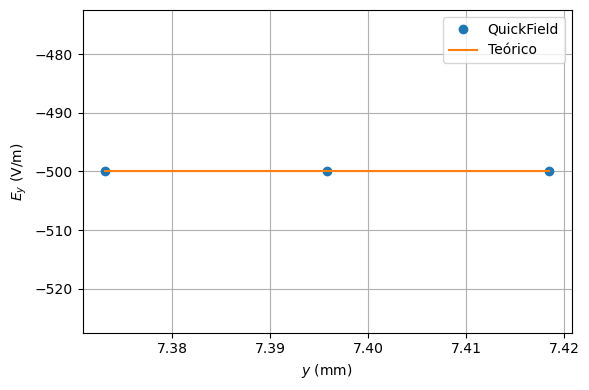

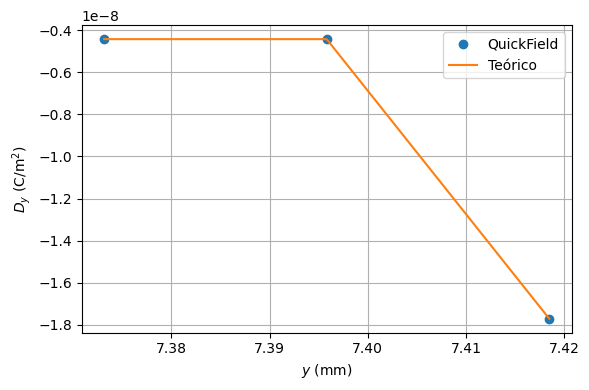

In [53]:
########################################################################################
# Archivo de QuickField
file_name = "condensador_plano.txt"

########################################################################################
# Leer archivo de QuickField (problema electrostático)
data = pd.read_csv(
    file_name,
    sep=r"\s+",
    skiprows=1,
    names=[
        "L_mm", "x_mm", "y_mm", "Nx", "Ny", "U_V", "E_V/m",
        "Ex_V/m", "Ey_V/m", "En_V/m", "Et_V/m",
        "D_C/m2", "Dx_C/m2", "Dy_C/m2", "Dn_C/m2", "Dt_C/m2",
        "epsilon_r", "w_J/m3"
    ]
)

########################################################################################
# Extraer datos
y_mm = data["y_mm"].values
y_m = y_mm * 1e-3

E_qf = data["Ey_V/m"].values
D_qf = data["Dy_C/m2"].values

########################################################################################
# Parámetros físicos
eps0 = 8.8541878128e-12  # F/m
V = 10.0                # V
d = 20e-3               # m

########################################################################################
# Campo eléctrico teórico (condensador plano ideal)
E_teo = -V / d * np.ones_like(y_m)

########################################################################################
# Desplazamiento eléctrico teórico
# D = eps0 * eps_r * E
# Como tienes dos materiales, tomamos eps_r local de QuickField
eps_r_local = data["epsilon_r"].values
D_teo = eps0 * eps_r_local * E_teo

########################################################################################
# Gráfica del campo eléctrico
plt.figure(figsize=(6, 4))
plt.plot(y_mm, E_qf, 'o', label='QuickField')
plt.plot(y_mm, E_teo, '-', label='Teórico')
plt.xlabel(r"$y$ (mm)")
plt.ylabel(r"$E_y$ (V/m)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("campo_electrico.png")
plt.show()

########################################################################################
# Gráfica del desplazamiento eléctrico
plt.figure(figsize=(6, 4))
plt.plot(y_mm, D_qf, 'o', label='QuickField')
plt.plot(y_mm, D_teo, '-', label='Teórico')
plt.xlabel(r"$y$ (mm)")
plt.ylabel(r"$D_y$ (C/m$^2$)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("desplazamiento_electrico.png")
plt.show()

# Espira Corriente.

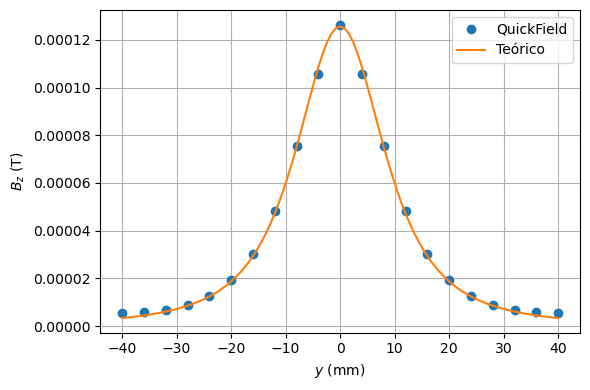

In [55]:
########################################################################################
# Cargar el archivo de texto
file_name = "espira_corriente.txt"

########################################################################################
# Leer ignorando el encabezado y asignando a cada columna su nombre

# (para problema magnetostático)
data = pd.read_csv(file_name, sep=r"\s+", skiprows=1,
                    names=["L_mm", "z_mm", "r_mm", "Nx", "Ny", "rA_Wb", "B_T",
                           "Bz_T", "Br_T", "Bn_T", "Bt_T", "H_A/m",
                           "Hz_A/m", "Hr_A/m", "Hn_A/m", "Ht_A/m", "mu_r", "w_J/m3"])

########################################################################################
# Extraer columnas de interés 
L = data["z_mm"]
Bz = data["Bz_T"]

# Modelo teórico: campo de una espira circular de corriente
mu0 = 4*np.pi*1e-7  # permeabilidad del vacío
I_espira = 2.5  # A
z = np.linspace(np.min(L), np.max(L), 101)
R = 12.50  # radio de la espira [mm]
Bz_teo = mu0*I_espira*(R*1e-3)**2 / 2 / ((z*1e-3)**2 + (R*1e-3)**2)**(3/2)

# Graficar
plt.figure(figsize=(6, 4))
plt.plot(L, Bz, 'o', label='QuickField')
plt.plot(z, Bz_teo, '-', label='Teórico')
plt.xlabel(r"$y$ (mm)")
plt.ylabel(r"$B_z$ (T)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Comprobación Q teórico y Simulado.

In [54]:
# Constantes
eps0 = 8.8541878128e-12  # F/m

# Tus datos (en metros)
ancho_total = 4e-3       # 4 mm
alto = 20e-3             # 20 mm
Lz = 10e-3               # 10 mm de profundidad
V = 10                   # Voltios

# Cada mitad tiene la mitad del ancho
ancho_mitad = ancho_total / 2
area_mitad = ancho_mitad * Lz  # m²
d = alto  # separación = alto del rectángulo

# Materiales
eps_r1 = 4  # izquierda
eps_r2 = 1  # derecha

# Cálculo
C1 = eps0 * eps_r1 * (area_mitad / d)
C2 = eps0 * eps_r2 * (area_mitad / d)
C_total = C1 + C2
Q_teorico = C_total * V

# Resultados
print(f"C1 = {C1:.3e} F")
print(f"C2 = {C2:.3e} F")
print(f"C_total = {C_total:.3e} F")
print(f"Q_teórico = {Q_teorico:.3e} C")
print(f"Q_simulado = 4.427e-13 C")
print(f"Diferencia = {abs(Q_teorico - 4.427e-13):.2e} C")

C1 = 3.542e-14 F
C2 = 8.854e-15 F
C_total = 4.427e-14 F
Q_teórico = 4.427e-13 C
Q_simulado = 4.427e-13 C
Diferencia = 9.39e-18 C
